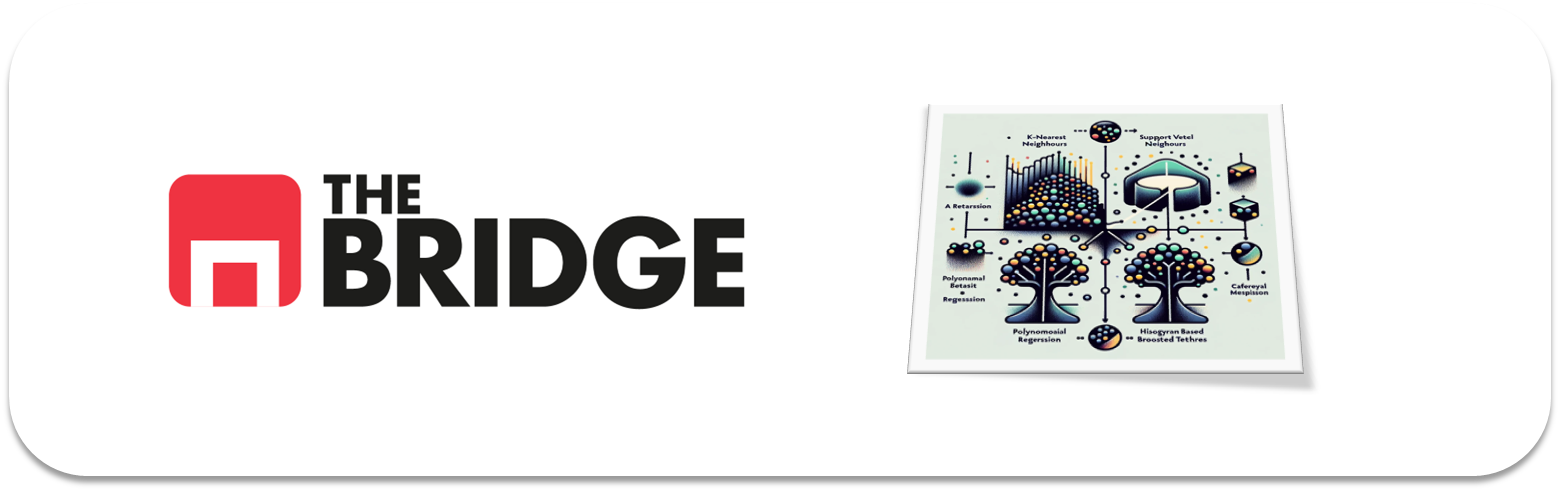

# Guía básica de un proyecto de Machine Learning supervisado

Esta guía resume, paso a paso, el proceso que hemos seguido a lo largo de las unidades de aprendizaje supervisado. Úsala como chuleta cuando te enfrentes a un problema nuevo.

Para que veas cada paso con datos reales, la guía trabaja con dos datasets:

- **Clasificación** → `bank-full.csv`: campaña de marketing telefónico de un banco portugués. El objetivo es predecir si un cliente contratará un depósito a plazo (`y`). Es el hilo principal de la guía.
- **Regresión** → `diamonds.csv`: características de unos 54 000 diamantes. El objetivo es predecir su precio (`price`). Lo usamos en los bloques específicos de regresión y en los pasos en los que aporta algo que el otro dataset no tiene.

⚠️ La guía muestra **un ejemplo de cada técnica**, no el mejor tratamiento posible para estos datasets. Cuando la apliques a tu problema, adapta los nombres de las columnas y las decisiones a tus datos.

## Paso 0: Importar librerías

Antes de empezar, cargamos las librerías necesarias para manejar datos, hacer gráficos, preparar nuestros datos y entrenar modelos. Esto nos permite tener todas las herramientas listas desde el principio.

In [ ]:
# Manipulación de datos
import pandas as pd
import numpy as np

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Modelado y preprocesamiento
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler

# Modelos de ejemplo
from sklearn.linear_model import LinearRegression, LogisticRegression, Ridge, Lasso, ElasticNet

# Métricas
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
from sklearn.metrics import root_mean_squared_error, r2_score

# pd.options.mode.copy_on_write = True # CoW por defecto en pandas 3.+

## Paso 1: Cargar datos

Primero necesitamos traer nuestros datos al entorno de trabajo. Normalmente vienen en archivos CSV, Excel o desde una base de datos. En esta etapa solo leemos los datos y echamos un primer vistazo rápido.

Fíjate en el separador: no todos los CSV usan comas (`bank-full.csv` usa `;`).

In [2]:
# Clasificación
df_clf = pd.read_csv("../data/bank-full.csv", sep=";")

# Primeras filas para ver cómo es el dataset
display(df_clf.head())

# Información básica del dataset
df_clf.info()

# Estadísticas básicas de las columnas numéricas
display(df_clf.describe())

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   age        45211 non-null  int64 
 1   job        45211 non-null  object
 2   marital    45211 non-null  object
 3   education  45211 non-null  object
 4   default    45211 non-null  object
 5   balance    45211 non-null  int64 
 6   housing    45211 non-null  object
 7   loan       45211 non-null  object
 8   contact    45211 non-null  object
 9   day        45211 non-null  int64 
 10  month      45211 non-null  object
 11  duration   45211 non-null  int64 
 12  campaign   45211 non-null  int64 
 13  pdays      45211 non-null  int64 
 14  previous   45211 non-null  int64 
 15  poutcome   45211 non-null  object
 16  y          45211 non-null  object
dtypes: int64(7), object(10)
memory usage: 5.9+ MB


,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


In [3]:
# Regresión
df_reg = pd.read_csv("../data/diamonds.csv")
display(df_reg.head())
df_reg.info()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53940 non-null  float64
 1   cut      53940 non-null  object 
 2   color    53940 non-null  object 
 3   clarity  53940 non-null  object 
 4   depth    53940 non-null  float64
 5   table    53940 non-null  float64
 6   price    53940 non-null  int64  
 7   x        53940 non-null  float64
 8   y        53940 non-null  float64
 9   z        53940 non-null  float64
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


## Paso 2: Definición del problema

Antes de tocar los datos, debemos saber qué queremos resolver:

- ¿Queremos predecir un valor numérico? → **Regresión**
- ¿Queremos clasificar en categorías? → **Clasificación**

Esto nos ayuda a decidir qué modelos y métricas usar.

**Advertencia:** a veces los targets son números pero representan categorías (por ejemplo, códigos de producto o clases). En ese caso es clasificación, no regresión.

En nuestros ejemplos: `y` ("yes"/"no") define un problema de clasificación binaria y `price`, uno de regresión.

In [4]:
target_clf = "y"
target_reg = "price"

# Pasamos el target de clasificación a 0/1 (1 = contrata el depósito), como esperan las métricas de sklearn
df_clf[target_clf] = (df_clf[target_clf] == "yes").astype(int)

## Paso 3: División en train y test

Antes de empezar a explorar o modelar los datos, siempre separamos una parte para evaluar nuestro modelo al final:

- **Train** → para explorar los datos, entrenar y comparar modelos.
- **Test** → para evaluar, una sola vez y al final, si el modelo generaliza bien.

Se suele usar un 70-80 % para train y un 20-30 % para test. A partir de aquí, todo lo que "aprenda" algo de los datos (EDA, imputaciones, escalados...) se hace solo con train.

Excepción: los duplicados que sean errores se eliminan **antes** del split (ver 6.2), para que una misma fila no acabe a la vez en train y en test.

In [5]:
# En clasificación con clases desbalanceadas, stratify mantiene la misma proporción de clases en train y en test
train_clf, test_clf = train_test_split(df_clf, test_size=0.2, random_state=42, stratify=df_clf[target_clf])

# En diamonds hay filas duplicadas: las eliminamos ANTES del split (ver 6.2)
print("Filas duplicadas en diamonds:", df_reg.duplicated().sum())
df_reg = df_reg.drop_duplicates()

train_reg, test_reg = train_test_split(df_reg, test_size=0.2, random_state=42)

Filas duplicadas en diamonds: 146


## Paso 4: Limpieza de los datos

Antes de explorar los datos, conviene hacer una revisión básica: valores faltantes, tipos de datos y duplicados.

De momento solo **miramos**: las imputaciones, las transformaciones y el escalado se hacen en el paso 6, calculando los valores necesarios (medias, medianas...) solo con train.

In [6]:
# Revisar valores faltantes
print(train_clf.isna().sum())

# Revisar duplicados
print("Filas duplicadas:", train_clf.duplicated().sum())

# Revisar tipos de datos
print(train_clf.dtypes)

age          0
job          0
marital      0
education    0
default      0
balance      0
housing      0
loan         0
contact      0
day          0
month        0
duration     0
campaign     0
pdays        0
previous     0
poutcome     0
y            0
dtype: int64
Filas duplicadas: 0
age           int64
job          object
marital      object
education    object
default      object
balance       int64
housing      object
loan         object
contact      object
day           int64
month        object
duration      int64
campaign      int64
pdays         int64
previous      int64
poutcome     object
y             int32
dtype: object


No hay ningún NaN... pero eso no significa que no falten datos. Muchos datasets codifican los faltantes con un valor especial (`"unknown"`, `-1`, `999`...). Revisa siempre los valores de las categóricas:

In [7]:
for col in train_clf.select_dtypes("object").columns:
    print(f"{col}: {(train_clf[col] == 'unknown').mean():.1%} de 'unknown'")

job: 0.6% de 'unknown'
marital: 0.0% de 'unknown'
education: 4.1% de 'unknown'
default: 0.0% de 'unknown'
housing: 0.0% de 'unknown'
loan: 0.0% de 'unknown'
contact: 28.7% de 'unknown'
month: 0.0% de 'unknown'
poutcome: 81.8% de 'unknown'


## Paso 5: Comprensión de variables, mini-EDA

### Pairplot inicial

Visualización rápida de varias variables a la vez. Útil para detectar patrones, clusters o interacciones importantes, especialmente cuando no hay demasiadas features continuas. Con datasets grandes, mejor pintar una muestra.

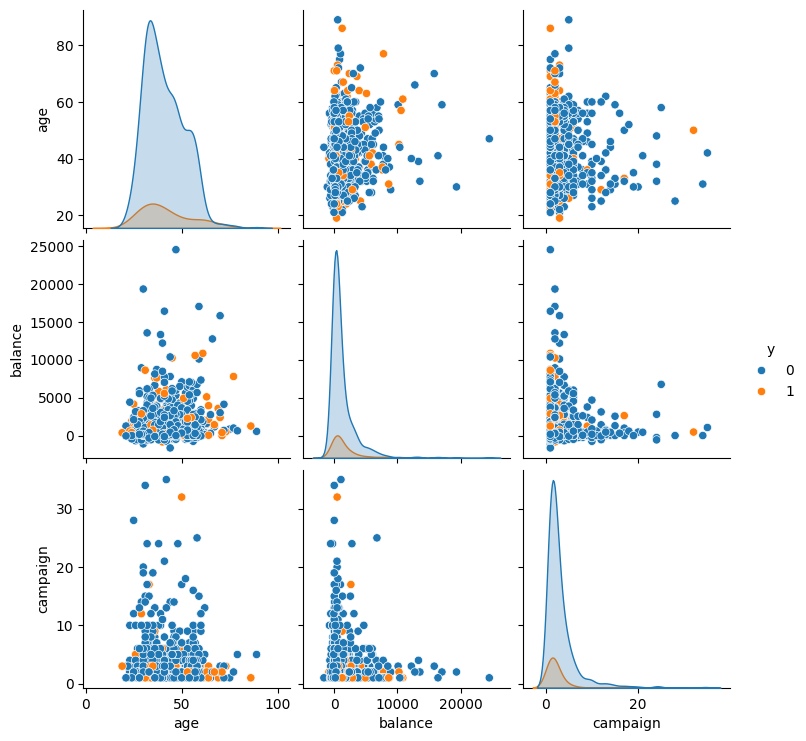

In [8]:
# hue=target solo en clasificación
sns.pairplot(train_clf[["age", "balance", "campaign", target_clf]].sample(1000, random_state=42), hue=target_clf)
plt.show()

### Estudio del target

Antes de mirar cualquier feature, observa tu variable objetivo. Comprueba su distribución y si está desbalanceada: esto influye en la elección de métricas y modelos. Para clasificación, revisa cuántas muestras hay de cada clase; para regresión, analiza la dispersión y posibles outliers.

y
0    0.883018
1    0.116982
Name: proportion, dtype: float64


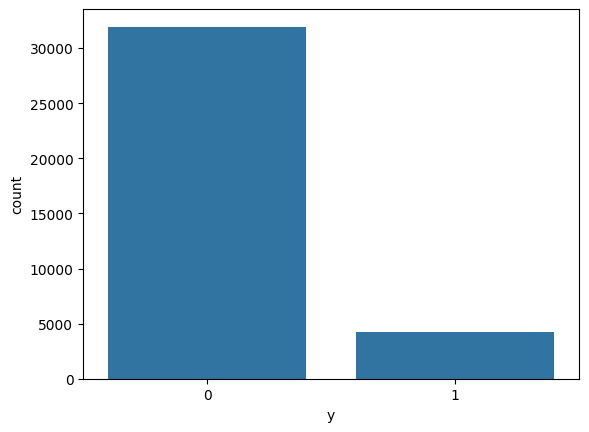

In [9]:
# Clasificación
print(train_clf[target_clf].value_counts(normalize=True))
sns.countplot(x=target_clf, data=train_clf)
plt.show()

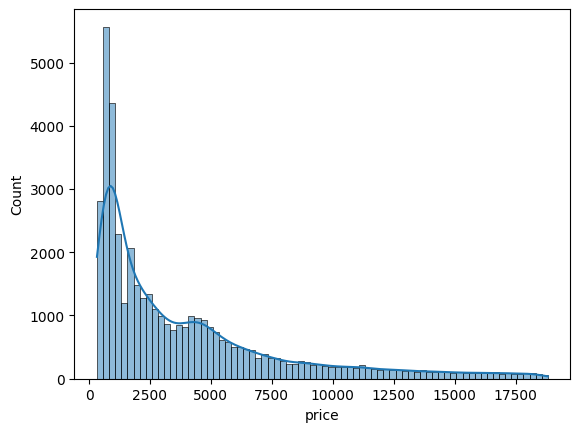

In [10]:
# Regresión
sns.histplot(train_reg[target_reg], kde=True)
plt.show()

*Solo un 12 % de los clientes contrata el depósito: un problema **desbalanceado**. Un modelo que dijera siempre "no" acertaría el 88 % de las veces, así que la accuracy no nos va a servir (paso 7). El precio de los diamantes, por su parte, tiene una cola larga a la derecha.*

### Análisis de correlaciones

Revisa cómo se relacionan tus features entre sí y con el target. Correlaciones muy altas pueden indicar redundancia; correlaciones con el target ayudan a ver qué features podrían ser más relevantes.

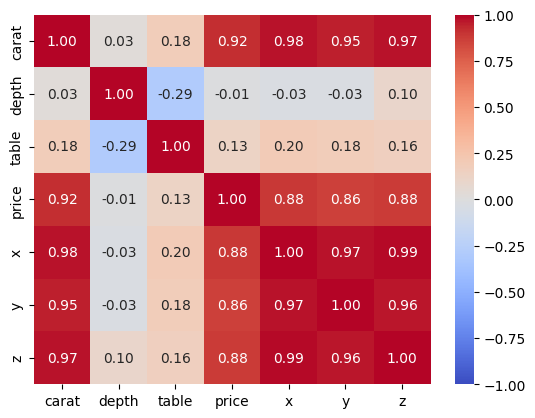

In [11]:
# Matriz de correlaciones
sns.heatmap(train_reg.corr(numeric_only=True), annot=True, fmt=".2f", vmin=-1, vmax=1, cmap="coolwarm")
plt.show()

Fijamos `vmin` y `vmax` en -1 y 1 para que la escala de colores cubra siempre todo el rango posible de la correlación y los colores sean comparables entre gráficos.

- Cuanto más cerca de 1, más correlación positiva; cuanto más cerca de -1, más correlación negativa.
- Cuanto más cerca de 0, más débil es la relación **lineal** (ojo: puede haber relaciones no lineales que la correlación no detecta).

El `cmap="coolwarm"` ayuda a verlo de un vistazo.

*En diamonds, `carat`, `x`, `y` y `z` están muy correlacionadas con el precio... y entre sí (el peso y las dimensiones miden prácticamente lo mismo).*

#### Advertencia sobre multicolinealidad:
Si dos o más features están muy correlacionadas entre sí, decimos que existe multicolinealidad. Esto puede afectar negativamente a algunos modelos (como la regresión lineal) porque dificulta que el modelo separe el efecto de cada variable: los coeficientes se vuelven inestables y difíciles de interpretar. En ese caso, conviene eliminar o combinar features muy correlacionadas antes de entrenar.

### Análisis univariante de features

Observa cada feature individualmente: distribución, valores extremos, posibles outliers. Esto te ayuda a detectar problemas antes de modelar.

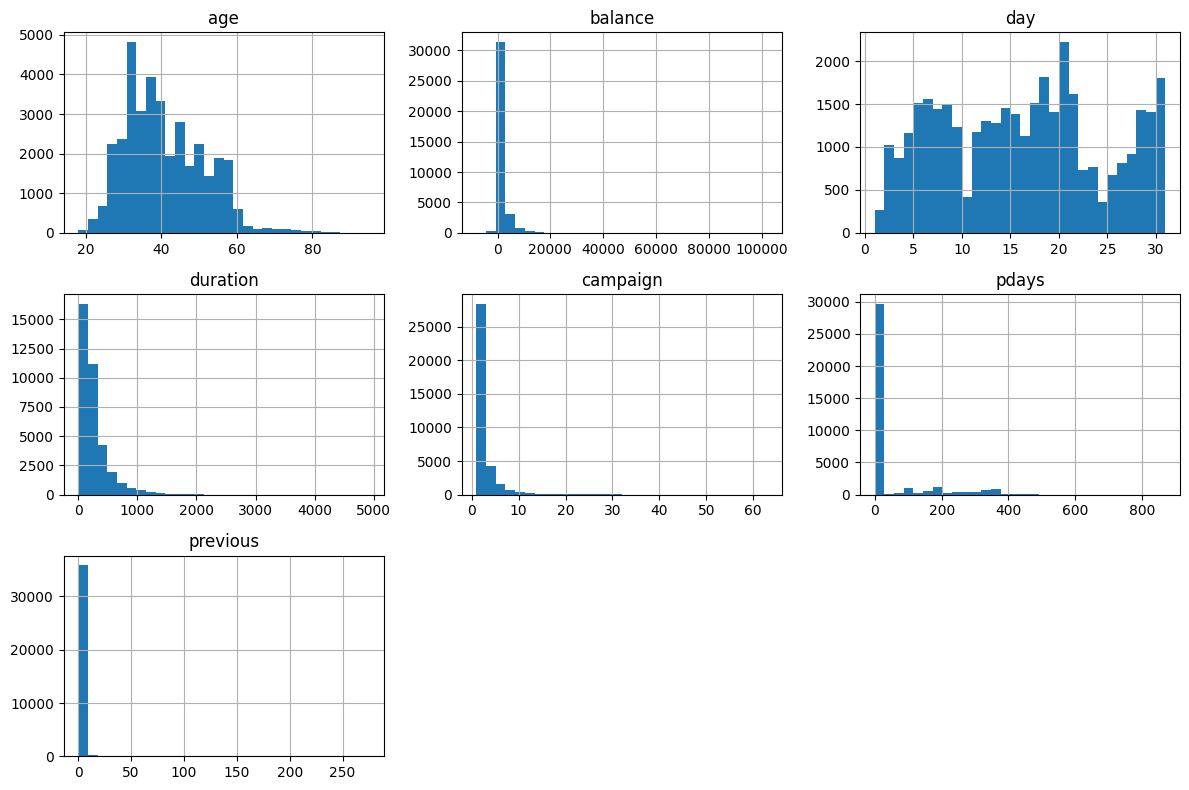

In [12]:
# Histograma de todas las features numéricas
train_clf.drop(columns=[target_clf]).hist(figsize=(12, 8), bins=30)
plt.tight_layout()
plt.show()

*`balance`, `duration`, `campaign`, `pdays` y `previous` son muy asimétricas, con colas largas a la derecha (en 6.5 y 6.6 veremos cómo tratar algunas). En `pdays` destaca un pico en -1: es el código para "nunca se le había contactado".*

### Análisis bivariante

Compara cada feature con el target o entre sí para ver relaciones. Para regresión, scatterplots; para clasificación, boxplots o violinplots con las numéricas, y la proporción de cada clase en cada categoría con las categóricas.

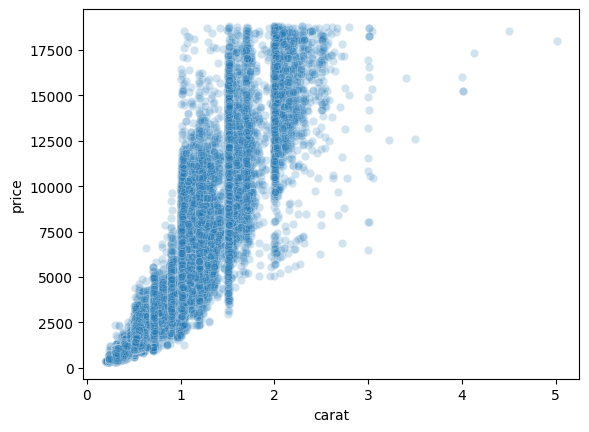

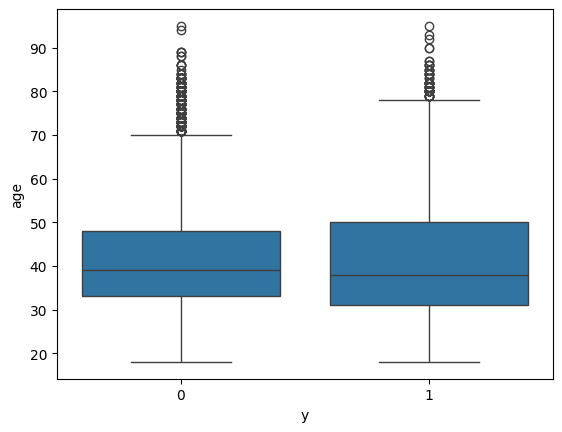

poutcome
success    0.646473
other      0.164983
failure    0.122911
unknown    0.092230
Name: y, dtype: float64

In [13]:
# Scatterplot para regresión
sns.scatterplot(x="carat", y=target_reg, data=train_reg, alpha=0.2)
plt.show()

# Boxplot para clasificación
sns.boxplot(x=target_clf, y="age", data=train_clf)
plt.show()

# Categórica frente a target de clasificación: tasa de "yes" por categoría
display(train_clf.groupby("poutcome")[target_clf].mean().sort_values(ascending=False))

*El precio crece claramente con el peso (y no de forma lineal). La edad apenas separa las clases, mientras que `poutcome` sí: los clientes que dijeron "sí" en la campaña anterior (`success`) contratan mucho más.*

## Paso 6: Tratamiento de variables

En este paso preparamos los datos para que puedan ser usados por modelos de Machine Learning. Incluye la eliminación de información poco útil, el tratamiento de problemas comunes en los datos y la creación o transformación de variables.

### 6.1 Eliminación de features
Tras el EDA, evaluamos si sobran variables. No todas las features aportan información predictiva y algunas pueden incluso perjudicar al modelo.

Suelen eliminarse:
- Features con valor constante.
- Features con muchos missings (≈ >20–30 %), salvo que el propio hecho de faltar aporte información.
- Identificadores (IDs, nombres propios).
- Strings largos sin tratamiento NLP.
- Categóricas con muchísimas categorías que no podamos agrupar ni codificar (ver 6.7).
- Features muy correlacionadas entre sí (multicolinealidad).
- ⚠️ Features que **no conoceremos en el momento de predecir** (fuga de información o *data leakage*).

Estas decisiones dependen del número total de features: cuantas más tengamos, más margen hay para eliminar.

*En bank, `duration` es la duración de la llamada: solo se conoce cuando la llamada ha terminado y, por tanto, ya sabemos si el cliente ha contratado. Si la dejáramos, el modelo parecería muy bueno pero sería inútil para decidir a quién llamar. La eliminamos.*

In [14]:
# Lo que quitemos de train hay que quitarlo también de test
train_clf = train_clf.drop(columns=["duration"])
test_clf = test_clf.drop(columns=["duration"])

### 6.2 Duplicados
Un duplicado no es necesariamente un error: dos filas iguales pueden ser dos observaciones reales distintas (dos clientes con el mismo perfil, dos diamantes idénticos). Antes de borrar nada, identifica qué define una fila única (cliente, pedido, cliente + fecha...):
- Si los duplicados son **errores** (cargas repetidas, registros dobles), elimínalos **antes del split**, en todo el dataset: si no, la misma fila puede acabar en train y en test e inflar la métrica de test. No es una fuga, porque eliminar duplicados no aprende nada de los datos.
- Si son **observaciones reales**, déjalos: reflejan que esa combinación es más frecuente.

*En diamonds no hay ningún identificador, así que no podemos saber si las filas repetidas son el mismo diamante cargado dos veces o dos diamantes iguales. Son muy pocas (146 de casi 54 000), así que el resultado apenas cambia. A título de ejemplo, las hemos eliminado en el paso 3, antes del split.*

In [15]:
# Ya lo hicimos en el paso 3 con diamonds, antes del split:
# df = df.drop_duplicates()

# Eliminar duplicados según una o varias columnas, cuando sabemos qué define una fila única
# (plantilla: en nuestros datasets no hay columna de cliente)
# df = df.drop_duplicates(subset=["cliente"], keep="last")

### 6.3 Missings (valores faltantes)
Un missing es un valor ausente (NaN), no un 0 ni un string vacío... aunque a veces viene disfrazado (`"unknown"`, `-1`).

La mayoría de modelos no los admiten, así que deben tratarse. Opciones principales:

- Eliminar filas o columnas (si son pocos).
- Imputar con media, mediana o moda.
- Imputar con un valor concreto.
- Imputación avanzada (KNN, modelos).
- Imputación + flag indicando que había missing.
- En categóricas, tratar el faltante como una categoría más, si su ausencia aporta información.

⚠️ Los valores para imputar se calculan **solo con train** y se aplican a train y a test.

*En bank: `job` y `education` tienen pocos "unknown" (1-4 %), así que los imputamos con la moda. En `contact` (29 %) y `poutcome` (82 %) son demasiados para imputar, y además significan algo ("no sabemos el canal", "no hubo campaña previa"): los dejamos como una categoría más.*

In [16]:
for col in ["job", "education"]:
    moda = train_clf.loc[train_clf[col] != "unknown", col].mode()[0]  # moda calculada SOLO con train
    train_clf[col] = train_clf[col].replace("unknown", moda)
    test_clf[col] = test_clf[col].replace("unknown", moda)
    print(f"{col}: 'unknown' -> '{moda}'")

# Con NaN de verdad, las alternativas serían:
# train_set = train_set.dropna()                                   # eliminar filas (solo en train)
# media = train_set["feature"].mean()                              # imputar con la media de train...
# train_set["feature"] = train_set["feature"].fillna(media)
# test_set["feature"] = test_set["feature"].fillna(media)          # ...y aplicarla también a test

job: 'unknown' -> 'blue-collar'
education: 'unknown' -> 'secondary'


### 6.4 Anomalías y errores
No son outliers, sino datos incorrectos:

- Valores negativos o iguales a cero imposibles.
- Fechas mal leídas (formato, año 9999).
- Problemas de encoding en texto.

Suelen tratarse como missings o corregirse manualmente tras revisión.

Ojo: no todo valor raro es un error. El -1 de `pdays` en bank es un código válido ("no contactado antes"), no una anomalía.

In [17]:
# En diamonds hay diamantes con alguna dimensión igual a 0 (imposible) o absurda (¡un diamante de casi 6 cm de ancho!)
display(train_reg[["x", "y", "z"]].describe())
print("Diamantes con alguna dimensión 0:", ((train_reg[["x", "y", "z"]] == 0).any(axis=1)).sum())

,x,y,z
count,43035.000000,43035.000000,43035.000000
mean,5.732834,5.736507,3.539274
std,1.125182,1.152466,0.697038
min,0.000000,0.000000,0.000000
25%,4.710000,4.720000,2.910000
50%,5.690000,5.710000,3.520000
75%,6.540000,6.540000,4.040000
max,10.740000,58.900000,8.060000


Diamantes con alguna dimensión 0: 15


*Podríamos tratarlas como missings e imputarlas, pero como `x`, `y` y `z` son redundantes con `carat` (multicolinealidad, ver correlaciones), la solución más sencilla es eliminar las tres columnas: resolvemos los dos problemas a la vez.*

In [18]:
train_reg = train_reg.drop(columns=["x", "y", "z"])
test_reg = test_reg.drop(columns=["x", "y", "z"])

### 6.5 Outliers
Valores atípicos que se alejan mucho del resto. Pueden perjudicar a los modelos basados en distancias (KNN, SVM) y a los lineales.

Detección:
- Gráficos (boxplot, histograma, scatter).
- Media ± N·desviación estándar, o rango intercuartílico (IQR).

Tratamiento:
- Eliminarlos.
- No hacer nada si usamos modelos basados en árboles, que son robustos a outliers en las features (KNN, SVM y los modelos lineales no lo son). Ojo: los outliers en el *target* sí afectan a un árbol de regresión.
- Transformaciones (log).
- Binning.
- Imputación.

Límite superior: 6.0 llamadas
Outliers en campaign: 2465 (6.8%)


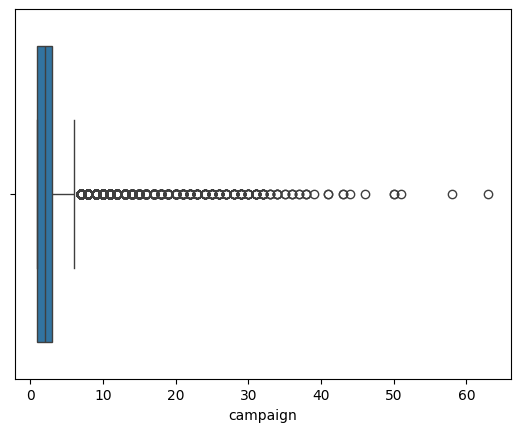

In [19]:
# Detección con el rango intercuartílico (IQR), calculado con train
q1, q3 = train_clf["campaign"].quantile([0.25, 0.75])
iqr = q3 - q1
limite_sup = q3 + 1.5 * iqr
print(f"Límite superior: {limite_sup} llamadas")
print(f"Outliers en campaign: {(train_clf['campaign'] > limite_sup).sum()} ({(train_clf['campaign'] > limite_sup).mean():.1%})")

sns.boxplot(x=train_clf["campaign"])
plt.show()

*Son muchos y no son errores (hay clientes a los que se llamó muchas veces), así que no los eliminamos: los suavizaremos con una transformación logarítmica en el siguiente paso.*

⚠️ Si eliminas outliers de X_train, elimina las mismas filas de y_train. Y nunca elimines filas de test: el modelo tendrá que enfrentarse a ellas en la realidad.

### 6.6 Transformaciones
Buscan mejorar la forma de la distribución (asimetría):

- Logarítmica (la más común). Solo para valores positivos: si hay ceros, `np.log1p` (log(1 + x)).
- Raíz cuadrada o cúbica.
- Box-Cox (solo valores positivos) o Yeo-Johnson (admite ceros y negativos).

Se evalúa con histogramas y con la asimetría (`skew`, cuanto más cerca de 0, más simétrica). Los tests de normalidad como el de Shapiro son poco útiles con muchos datos: rechazan la normalidad ante cualquier pequeña desviación.

In [20]:
features_log = ["campaign", "previous"]

print("Skew antes:\n", train_clf[features_log].skew().round(2))

# log1p porque previous tiene ceros. Es una transformación fija (no aprende nada), se aplica igual a train y a test
train_clf[features_log] = np.log1p(train_clf[features_log])
test_clf[features_log] = np.log1p(test_clf[features_log])

print("Skew después:\n", train_clf[features_log].skew().round(2))

Skew antes:
 campaign     4.94
previous    45.03
dtype: float64
Skew después:
 campaign    1.33
previous    2.54
dtype: float64


*`balance` también es muy asimétrica, pero tiene valores negativos (descubiertos): ahí no vale el log, habría que usar Yeo-Johnson. La dejamos como está para no alargar la guía.*

Las transformaciones también sirven para **linealizar relaciones**. En diamonds, la relación entre peso y precio es curva, pero se vuelve casi una recta si aplicamos el logaritmo a **las dos** variables:

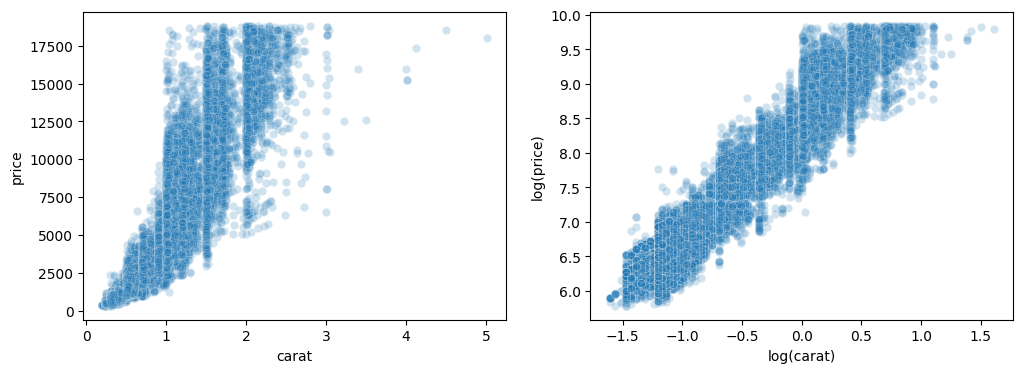

In [21]:
fig, axs = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(x=train_reg["carat"], y=train_reg[target_reg], alpha=0.2, ax=axs[0])
sns.scatterplot(x=np.log(train_reg["carat"]), y=np.log(train_reg[target_reg]), alpha=0.2, ax=axs[1])
axs[1].set_xlabel("log(carat)")
axs[1].set_ylabel("log(price)")
plt.show()

*Ojo: transformar solo `carat` empeoraría el modelo lineal. Y si transformamos el target, el modelo predice log(precio): hay que deshacer la transformación (`np.exp`) antes de calcular las métricas en dólares. Para no complicar la guía, aquí dejamos ambas variables como están.*

### 6.7 Encodings (variables categóricas)

Los modelos no admiten texto, hay que convertirlo a números.

Elección según el tipo de variable:
- Binaria → mapeo 0/1.
- Ordinal → mapeo respetando el orden.
- No ordinal → one-hot / dummies.
- Alta cardinalidad → agrupar las categorías poco frecuentes, frequency encoding o hashing.

In [22]:
# Binarias (bank): mapeo 0/1
for col in ["default", "housing", "loan"]:
    train_clf[col] = (train_clf[col] == "yes").astype(int)
    test_clf[col] = (test_clf[col] == "yes").astype(int)

# Ordinal (bank): respetando el orden
orden_education = {"primary": 0, "secondary": 1, "tertiary": 2}
train_clf["education"] = train_clf["education"].map(orden_education)
test_clf["education"] = test_clf["education"].map(orden_education)

# Ordinales (diamonds): de peor a mejor calidad
orden_cut = {"Fair": 0, "Good": 1, "Very Good": 2, "Premium": 3, "Ideal": 4}
orden_color = {"J": 0, "I": 1, "H": 2, "G": 3, "F": 4, "E": 5, "D": 6}
orden_clarity = {"I1": 0, "SI2": 1, "SI1": 2, "VS2": 3, "VS1": 4, "VVS2": 5, "VVS1": 6, "IF": 7}
for col, orden in [("cut", orden_cut), ("color", orden_color), ("clarity", orden_clarity)]:
    train_reg[col] = train_reg[col].map(orden)
    test_reg[col] = test_reg[col].map(orden)

In [23]:
# No ordinales (bank): one-hot encoding
features_onehot = ["job", "marital", "contact", "month", "poutcome"]
train_clf = pd.get_dummies(train_clf, columns=features_onehot, dtype=int)
test_clf = pd.get_dummies(test_clf, columns=features_onehot, dtype=int)

# Si alguna categoría solo aparece en train o en test, las columnas no coincidirán: las alineamos con las de train
# (el OneHotEncoder de sklearn, dentro de un Pipeline, lo resuelve automáticamente)
test_clf = test_clf.reindex(columns=train_clf.columns, fill_value=0)

print("Columnas tras el encoding:", train_clf.shape[1])

Columnas tras el encoding: 44


⚠️ Codificar siempre usando train, y aplicar lo mismo a test.

### 6.8 Escalado

Pone todas las variables en la misma escala:

- StandardScaler (media 0, desviación estándar 1).
- MinMaxScaler (rango 0–1).

Importante para modelos basados en distancias (KNN, SVM) y para los que llevan regularización (Ridge, Lasso, ElasticNet y la regresión logística, que regulariza por defecto): la penalización depende del tamaño de los coeficientes, y este depende de la escala de cada feature. También ayuda a que los optimizadores converjan antes. No afecta a los árboles ni a las predicciones de una regresión lineal sin regularizar.

In [24]:
# Las binarias y las dummies (0/1) no hace falta escalarlas; con ordinales de pocos valores (education) es opcional
features_num_clf = ["age", "balance", "day", "campaign", "pdays", "previous"]
scaler_clf = StandardScaler()
train_clf[features_num_clf] = scaler_clf.fit_transform(train_clf[features_num_clf])  # fit SOLO con train
test_clf[features_num_clf] = scaler_clf.transform(test_clf[features_num_clf])

# En diamonds escalamos también las ordinales (cut, color, clarity): tienen más valores y vamos a usar Ridge y Lasso
features_num_reg = ["carat", "cut", "color", "clarity", "depth", "table"]
scaler_reg = StandardScaler()
train_reg[features_num_reg] = scaler_reg.fit_transform(train_reg[features_num_reg])
test_reg[features_num_reg] = scaler_reg.transform(test_reg[features_num_reg])

## Paso 7: Elección de métricas

Ningún modelo es perfecto: siempre comete errores. Por eso necesitamos una métrica, que nos sirva para:
- Comparar distintos modelos y elegir el mejor.
- Comunicar resultados de forma clara y honesta.

La métrica debe elegirse según el tipo de problema y el contexto, no solo porque sea la más conocida. La mayoría están implementadas en sklearn.

### 7.1 Métricas para clasificación
#### Accuracy
- Porcentaje total de aciertos.
- Fácil de entender.
- Poco informativa si las clases están desbalanceadas.

#### Matriz de confusión
Muestra en qué se equivoca el modelo.
- TP: positivos bien clasificados
- TN: negativos bien clasificados
- FP: falsos positivos
- FN: falsos negativos

Es la base para entender el resto de métricas.

#### Recall (sensibilidad)
De todos los positivos reales, cuántos detecta el modelo.

Importante cuando no queremos FN.

Ejemplo típico: detección de enfermedades.

#### Precision
De todos los positivos predichos, cuántos son correctos.

Importante cuando no queremos FP.

Ejemplo: filtro de spam.

#### F1-score
Media armónica de precision y recall.
- Útil cuando queremos un equilibrio entre ambas.
- Solo es alto si las dos lo son, pero no dice cuál de las dos falla: mira siempre también precision y recall.

#### Curvas precision–recall
Permiten analizar el comportamiento del modelo cambiando el threshold.
- Útiles cuando las clases están desbalanceadas.
- Ayudan a elegir el punto óptimo según el problema.

#### Curva ROC y AUC
Relaciona el recall con la tasa de falsos positivos.
- AUC mide el rendimiento global del clasificador.
- AUC ≈ 1 → buen modelo
- AUC ≈ 0.5 → modelo aleatorio

Más usada en datasets balanceados.

#### ¿Cómo saber qué métrica de clasificación usar?
Imagina un modelo que detecta si un email es spam. Si solo miramos accuracy, puede parecer muy bueno porque acierta casi todo, pero quizá falla justo en los correos importantes. Recall sería clave si no queremos que se nos escape ningún spam (aunque marque algún correo bueno como spam), mientras que precision es más importante si nos preocupa no perder ningún correo importante. La matriz de confusión nos permite ver exactamente en qué se equivoca el modelo: qué correos confunde y cómo. Cuando no está claro si priorizar recall o precision, usamos el F1-score, que busca un equilibrio entre ambos. Si además queremos analizar cómo cambia el comportamiento del modelo al ser más o menos estricto, usamos curvas como ROC o precision–recall, que nos ayudan a elegir el punto óptimo según el coste real de cada tipo de error.

*En bank, la accuracy no sirve (88 % diciendo siempre "no"). Al banco le interesa encontrar a los clientes que contratarían (recall) sin hacer demasiadas llamadas en balde (precision): usaremos el **F1** para elegir el modelo.*

### 7.2 Métricas para regresión
#### R² (coeficiente de determinación)
- Mide la proporción de variabilidad explicada por el modelo.
- No indica por sí solo si el modelo es bueno.
- Puede ser engañoso si se usa sin contexto.

#### MSE (Mean Squared Error)
- Media del error al cuadrado.
- Penaliza mucho los errores grandes.
- Útil para comparar modelos, no para explicar resultados.

#### RMSE (Root MSE)
- Raíz del MSE, en las unidades del target.
- Más interpretable que MSE.
- Muy usada para reportar resultados.

#### MAE (Mean Absolute Error)
- Error medio absoluto.
- Fácil de interpretar.
- Más robusta frente a outliers.

#### MAPE (Mean Absolute Percentage Error)
- Error medio en porcentaje respecto al valor real.
- Útil para comparar errores entre targets con escalas distintas.
- No está acotado por arriba: un error del 300 % es posible. Ojo: sklearn lo devuelve en tanto por uno (0.05 = 5 %).
- Problemas si el target tiene valores cercanos a 0.

*En diamonds usaremos el RMSE (en dólares) y el R².*

## Paso 8: Selección del modelo

No existe un modelo “mejor” en general: el modelo adecuado depende de los datos y del objetivo del problema. Antes de entrenar, conviene tener en cuenta varios factores clave.

### Volumen de datos y número de features
- Pocos datos y muchas variables: conviene usar modelos simples, con mayor sesgo pero que generalizan mejor (regresiones lineal y logística con regularización, SVM lineal).
- Muchos datos y pocas variables: se pueden usar modelos más complejos, capaces de capturar patrones más finos (árboles de decisión, random forest, boosting). KNN también puede funcionar, pero se vuelve lento al predecir con muchos datos.
### Rendimiento vs interpretabilidad
- Uno de los compromisos más importantes.
- Modelos interpretables (“caja blanca”) permiten explicar por qué toman una decisión (regresiones lineal y logística, árboles de decisión poco profundos).
- Modelos más complejos (“caja negra”) suelen ser más precisos, pero difíciles de explicar (ensembles, redes neuronales).
- La elección depende de si necesitamos justificar las decisiones del modelo.
### Velocidad de entrenamiento
- Rápidos: regresiones lineal y logística, árboles de decisión.
- Lentos: SVM con muchos datos (especialmente con tuning), ensembles grandes, redes neuronales. KNN entrena al instante, pero es lento al predecir.
- Esto es importante cuando hay muchos datos o poco tiempo de cómputo.
### Tipo de relación entre los datos
- Si la relación con el target es aproximadamente lineal, los modelos lineales suelen funcionar bien.
- Si existen relaciones no lineales, conviene usar modelos más flexibles como árboles, random forest, boosting, KNN o redes neuronales.
- Esto se detecta principalmente durante el EDA.

## Paso 9: Entrenamiento del modelo

En este paso el modelo aprende patrones a partir de los datos de entrenamiento. El objetivo no es solo que funcione bien en train, sino que generalice correctamente a datos nuevos.

Antes de entrenar, es importante:
- Haber separado correctamente train y test.
- Aplicar el preprocesado solo con train.
- Definir claramente la métrica con la que se evaluará el modelo.

Durante el entrenamiento:
- Se entrena primero un modelo base (baseline) sin mucho ajuste.
- Después, si es necesario, se prueban otros modelos o se ajustan hiperparámetros.
- El uso de pipelines asegura que el preprocesado y el modelo se apliquen siempre de forma consistente y sin fugas de información (en esta guía hemos hecho los pasos a mano para que se vean uno a uno).

Tras entrenar:
- Los modelos se comparan y se ajustan con validación cruzada sobre train, nunca mirando el test.
- El test se usa una sola vez, al final, con el modelo elegido. Comparar su métrica con la de train ayuda a detectar overfitting.
- Se decide si el rendimiento es suficiente o si hay que volver a pasos anteriores (features, modelo o métrica).

In [25]:
# Separamos features y target
X_train_clf = train_clf.drop(columns=[target_clf])
y_train_clf = train_clf[target_clf]
X_test_clf = test_clf.drop(columns=[target_clf])
y_test_clf = test_clf[target_clf]

X_train_reg = train_reg.drop(columns=[target_reg])
y_train_reg = train_reg[target_reg]
X_test_reg = test_reg.drop(columns=[target_reg])
y_test_reg = test_reg[target_reg]

# Baselines: modelos sencillos, sin ajustar
model_clf = LogisticRegression(max_iter=1000)
model_clf.fit(X_train_clf, y_train_clf)

model_reg = LinearRegression()
model_reg.fit(X_train_reg, y_train_reg)

print("F1 baseline (CV):", round(cross_val_score(model_clf, X_train_clf, y_train_clf, cv=5, scoring="f1").mean(), 3))
print("RMSE baseline (CV):", round(-cross_val_score(model_reg, X_train_reg, y_train_reg, cv=5, scoring="neg_root_mean_squared_error").mean(), 2))

F1 baseline (CV): 0.276
RMSE baseline (CV): 1240.41


## Paso 10: Ajuste de hiperparámetros y regularización

### Elegir hiperparámetros

Como ya sabes, cada dataset es de su padre y de su madre, así que no podemos saber de antemano qué modelo y qué hiperparámetros se ajustarán mejor a los datos: hay que probar varias combinaciones. Por suerte, sklearn tiene `GridSearchCV`, que prueba todas las combinaciones de un grid con validación cruzada de forma automatizada.

Empieza con unos pocos valores de cada hiperparámetro y ve afinando según los resultados de cada ejecución.

En este apartado verás posibles grids para los algoritmos más utilizados.

In [26]:
# REGRESIÓN LOGÍSTICA
grid_logreg = {
    "l1_ratio": [0, 1],          # Tipo de regularización: 0 = L2 (por defecto), 1 = L1 (desde sklearn 1.8; antes, penalty="l2"/"l1")
    "C": [0.1, 0.5, 1.0, 5.0],   # Inversa de la fuerza de la regularización: cuanto más bajo, más regularización
    "solver": ["liblinear"]      # Admite tanto L1 como L2
}
# max_iter no se suele ajustar: basta con ponerlo alto (por ejemplo 1000) en el modelo si aparecen avisos de convergencia

# ÁRBOL DE DECISIÓN
grid_arbol = {
    "max_depth": list(range(1, 10)),
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 5]
}

# RANDOM FOREST
grid_random_forest = {
    "n_estimators": [120],               # Más árboles no empeoran el modelo, pero a partir de cierto número no merece la pena
                                          # el tiempo extra porque apenas mejora. Entre 100 y 200 es una buena cifra
    "max_depth": [3, 4, 5, 6, 10, 15, 17], # Le afecta menos el overfitting que a un árbol de decisión:
                                          # podemos probar profundidades mayores
    "max_features": ["sqrt", 3, 4]       # Número de features que se consideran en cada split:
                                          # cuanto más bajo, más diferentes son los árboles y menos overfitting
}

# GRADIENT BOOSTING (clasificación)
grid_gradient_boosting = {
    "learning_rate": [0.05, 0.1, 0.2, 0.4, 0.5],  # Cuanto más alto, más aporta cada nuevo árbol
    "n_estimators": [20, 50, 100, 200],          # Cuidado con poner muchos estimadores (sobre todo con learning_rate alto):
                                                # podemos sobreajustar el modelo
    "max_depth": [1, 2, 3, 4, 5],                # No hace falta mucha profundidad: cada nuevo árbol corrige los errores de los anteriores
    "max_features": ["sqrt", 3, 4]              # Igual que en el random forest
}

Ejemplo de uso completo:

In [27]:
# Modelo base
model = LogisticRegression(max_iter=1000)

# Grid de hiperparámetros: además de C, probamos class_weight="balanced", que da más peso a la clase minoritaria
param_grid = {
    "C": [0.01, 0.1, 1, 10],
    "class_weight": [None, "balanced"]
}

# GridSearch
grid = GridSearchCV(
    estimator=model,
    param_grid=param_grid,
    cv=5,
    scoring="f1",   # la métrica elegida en el paso 7
    n_jobs=-1
)

# Entrenamiento SOLO con train
grid.fit(X_train_clf, y_train_clf)

# Mejor modelo encontrado
best_model_clf = grid.best_estimator_

print("Mejores hiperparámetros:", grid.best_params_)
print("Mejor F1 en CV:", round(grid.best_score_, 3))

Mejores hiperparámetros: {'C': 10, 'class_weight': 'balanced'}
Mejor F1 en CV: 0.374


*El mejor valor de `C` (10) está en el borde del grid: cuando ocurre esto, el óptimo podría estar más allá, así que conviene ampliar el grid (por ejemplo, `[10, 50, 100]`) y volver a buscar.*

### Regularización: controlando el sobreajuste
La regularización sirve para evitar que el modelo se adapte demasiado a los datos de entrenamiento (overfitting), penalizando coeficientes grandes o complejidad excesiva.
- L1 (Lasso): penaliza la suma de valores absolutos de los coeficientes. Puede eliminar features innecesarias.
- L2 (Ridge): penaliza la suma de los cuadrados de los coeficientes. Reduce los coeficientes grandes, pero no los anula.
- ElasticNet: combina L1 y L2.

In [28]:
# Comparamos con validación cruzada sobre train (el test se reserva para el final)
modelos_reg = {
    "Lineal (sin regularizar)": LinearRegression(),
    "Ridge (L2)": Ridge(alpha=1.0),
    "Lasso (L1)": Lasso(alpha=10),
    "ElasticNet (L1 + L2)": ElasticNet(alpha=0.1, l1_ratio=0.5),
}

for nombre, modelo in modelos_reg.items():
    rmse = -cross_val_score(modelo, X_train_reg, y_train_reg, cv=5, scoring="neg_root_mean_squared_error").mean()
    print(f"{nombre}: RMSE en CV = {rmse:.0f} $")

Lineal (sin regularizar): RMSE en CV = 1240 $
Ridge (L2): RMSE en CV = 1240 $
Lasso (L1): RMSE en CV = 1241 $
ElasticNet (L1 + L2): RMSE en CV = 1265 $


- alpha controla la fuerza de la penalización: más alto → más regularización.
- Ridge suaviza todos los coeficientes; Lasso puede dejar algunos en cero.
- ElasticNet es útil si queremos un equilibrio entre ambos.
- En la práctica, alpha también se ajusta con validación cruzada (`GridSearchCV`), no mirando el test.

*En diamonds, regularizar no mejora nada: con unas 43 000 filas y solo 6 features, el modelo lineal no sobreajusta, así que no hay nada que corregir (ElasticNet incluso empeora un poco porque penaliza de más). La regularización marca la diferencia con pocos datos o muchas features.*

## Paso 11: Evaluación

Una vez elegidas las métricas y evaluados varios modelos, ya tenemos los resultados del modelo. Solo queda interpretarlos, y por desgracia este punto depende mucho del negocio.

1. Evaluar los resultados en test: comprobar que no difieren mucho de los de entrenamiento. Si son bastante peores en test, el modelo está sobreajustado (overfitting; ver abajo cómo reducirlo). Si son mejores, suele ser casualidad (por ejemplo, un test pequeño): conviene confirmarlo con validación cruzada.
2. Evaluar los resultados respecto a las necesidades de negocio.
3. Guardar los datos utilizados en el entrenamiento, los scripts y el propio modelo entrenado. La puesta en producción queda fuera del objetivo de esta guía.
4. Elegir la métrica o métricas con las que presentaremos los resultados. No tiene por qué ser la misma que usamos para buscar el mejor modelo, porque no todas son fáciles de entender (por ejemplo, el MSE o el AUC).

**¿Qué hacer si tenemos overfitting?**

- Validación cruzada: no evita el overfitting por sí misma, pero permite detectarlo y elegir los hiperparámetros que lo reducen sin mirar el test.
- Entrenar con más datos: no quitándoselos al test, sino consiguiendo más.
- Eliminar features: un algoritmo de selección de features (o técnicas de reducción de dimensionalidad, que verás en aprendizaje no supervisado) puede ayudar.
- Max depth: reducirlo si trabajamos con árboles.
- Regularización: aumentarla en los modelos que la permiten, como las regresiones lineal y logística o los SVM.
- Ensembles: sobre todo los de bagging, como el random forest, que suelen sobreajustar menos que un árbol individual.

Ejemplo de regresión:

In [29]:
# Predicciones
y_train_pred = model_reg.predict(X_train_reg)
y_test_pred = model_reg.predict(X_test_reg)

# Evaluación
print("Train RMSE:", round(root_mean_squared_error(y_train_reg, y_train_pred), 2))
print("Test RMSE:", round(root_mean_squared_error(y_test_reg, y_test_pred), 2))
print("Train R2:", round(r2_score(y_train_reg, y_train_pred), 3))
print("Test R2:", round(r2_score(y_test_reg, y_test_pred), 3))

# Validación cruzada (sobre train)
cv_scores = cross_val_score(model_reg, X_train_reg, y_train_reg, cv=5, scoring="r2")
print("R2 en validación cruzada:", round(cv_scores.mean(), 3))

Train RMSE: 1240.4
Test RMSE: 1203.66
Train R2: 0.904
Test R2: 0.905
R2 en validación cruzada: 0.904


- Si el RMSE de train es mucho menor que el de test → overfitting.
- Si el R2 de train es mucho mayor que el de test → overfitting.
- La validación cruzada nos da una idea más robusta del rendimiento general del modelo.

Ejemplo de clasificación:

Train F1: 0.379
Test F1: 0.378
Test Accuracy: 0.757
Test Precision: 0.27
Test Recall: 0.631


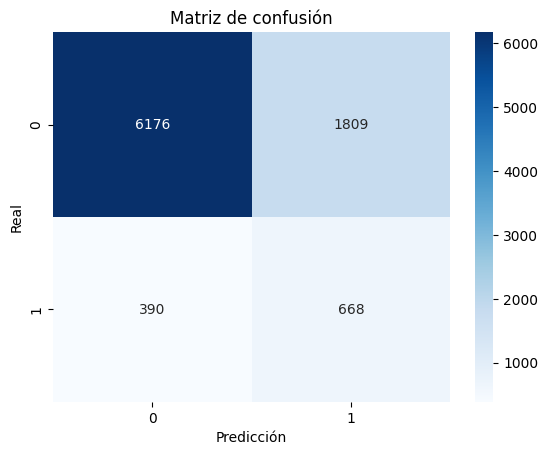

In [30]:
# Predicciones con el modelo elegido en el GridSearch
y_train_pred = best_model_clf.predict(X_train_clf)
y_test_pred = best_model_clf.predict(X_test_clf)

# Métricas (precision, recall y F1 tal cual, para clasificación binaria; en multiclase añade average='macro')
print("Train F1:", round(f1_score(y_train_clf, y_train_pred), 3))
print("Test F1:", round(f1_score(y_test_clf, y_test_pred), 3))
print("Test Accuracy:", round(accuracy_score(y_test_clf, y_test_pred), 3))
print("Test Precision:", round(precision_score(y_test_clf, y_test_pred), 3))
print("Test Recall:", round(recall_score(y_test_clf, y_test_pred), 3))

# Matriz de confusión
c_matrix = confusion_matrix(y_test_clf, y_test_pred)
sns.heatmap(c_matrix, annot=True, fmt="d", cmap="Blues")
plt.xlabel("Predicción")
plt.ylabel("Real")
plt.title("Matriz de confusión")
plt.show()

Interpretación:
- Si la métrica de train es mucho mejor que la de test → overfitting.
- Precision y recall ayudan a entender los errores según la clase:
  - Recall alto → pocos falsos negativos.
  - Precision alta → pocos falsos positivos.
- La matriz de confusión muestra en detalle en qué se confunde el modelo.
- La validación cruzada (el `best_score_` del GridSearch) da una medida más estable del rendimiento del modelo.

*En diamonds, train y test dan prácticamente el mismo R² (0.90) y un RMSE parecido (1 240 $ en train y 1 204 $ en test): no hay overfitting. Que test salga incluso un poco mejor es casualidad del reparto, como confirma la validación cruzada (R² de 0.90).*

*En bank, train y test también coinciden (F1 de 0.38), así que tampoco hay overfitting... pero un F1 tan bajo incluso en train apunta a **underfitting**: o el modelo es demasiado sencillo para el problema, o a las features les falta información para separar las clases. Fíjate en que su accuracy (76 %) es peor que la de decir siempre "no" (88 %) y, aun así, es mucho más útil: detecta el 63 % de los clientes que contratan (recall), a cambio de que solo 1 de cada 4 clientes que señala acabe contratando (precision de 0.27). Para mejorarlo, probaríamos modelos no lineales (random forest, boosting) y ajustaríamos el umbral de decisión con la curva precision–recall.*

## Paso 12: Conclusión

Al finalizar un proyecto de ML, las conclusiones deben centrarse en estos puntos:
1. Rendimiento general del modelo
- Qué tal predice sobre los datos de test.
- Métricas clave (F1, recall, R², RMSE, etc.) y su interpretación concreta, en lenguaje de negocio.
2. Errores y limitaciones
- Identificar patrones de error: qué casos falla más y por qué.
- Posibles sesgos: datos desbalanceados, features que afectan demasiado o poco.
- Riesgos de overfitting o underfitting.
3. Importancia de variables / interpretabilidad
- Qué features fueron más determinantes en las predicciones.
- Cómo esas variables se relacionan con el resultado esperado.
4. Aplicabilidad para el negocio o contexto
- Cómo los resultados ayudan a la toma de decisiones.
- Limitaciones prácticas: casos donde no conviene usar el modelo o donde los errores pueden ser críticos.
5. Recomendaciones futuras
- Mejoras posibles: más datos, refinamiento de features, ajuste de hiperparámetros, pruebas con otros modelos.
- Estrategias para mantener el modelo actualizado y confiable en producción.

**Ejemplo de redacción para presentar resultados (bank):**

*“Si el banco llamara solo a los clientes que señala el modelo (algo más de una cuarta parte de la cartera), encontraría al 63 % de los que acabarían contratando el depósito, y una de cada cuatro llamadas terminaría en contratación: más del doble que llamando al azar (12 %). El modelo es estable (rinde igual en train y en test), pero sencillo: el siguiente paso es probar modelos basados en árboles y ajustar el umbral según el coste de cada llamada. Por último, hemos excluido la duración de la llamada, que solo se conoce después de hacerla y habría inflado artificialmente los resultados.”*